**DSA 405-002 · Fall 2026 · P4: Project Synthesis**
Riley Hoover (rdhoover) · `DSA405_002_FA26_P4_rdhoover.ipynb`

**Question (unchanged from P1 through P3):** does a monthly top-10 momentum strategy, picked from Nasdaq's 100 highest-volume names, beat buy-and-hold on the S&P 500 (SPY) across roughly 30 years?

The question itself did not change. The method did. The Nasdaq Symbol Directory has no volume column, so the study pulls prices for every Nasdaq Global Select common stock in good standing on the 2026-09-17 snapshot, ranks those names each month by average daily dollar volume, and buys the top 10 of the 100 highest-dollar-volume names. Dollar volume is used because Yahoo's close and volume are already split-adjusted. This is a solo project, declared Tier 1, with no stretch component.

**What this notebook does.** It starts from the audited raw Nasdaq file and the saved Yahoo cache (restored by `scripts/get_data.py` if needed), rebuilds the monthly joined table, reruns the P3 headline backtest with the 21 flagged returns kept, and then adds the P4 sensitivity and uncertainty checks. Figures go to `figures/`. Headline numbers go to `results/findings.csv`. This notebook does not contact Yahoo and does not submit anything.


In [1]:
# Setup: imports, folders, and every constant the notebook uses, in one place.
import hashlib, json, re, subprocess, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

ROOT = Path(".").resolve()
RAW = ROOT / "data" / "raw"
YAHOO_RAW = RAW / "yahoo"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
for folder in (YAHOO_RAW, PROCESSED, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

NASDAQ_RAW = RAW / "nasdaqtraded.txt"
NASDAQ_SHA256 = "61eaccdf817442beaceada8ce5fc0a84f8c4db865564d8a474e7dea9189318d0"

CHART_URL = "https://query1.finance.yahoo.com/v8/finance/chart/{ticker}"
USER_AGENT = ("DSA405-002-FA26-NCSU-student/1.0 "
              "(educational non-commercial class project; Riley Hoover; rdh.oliver@gmail.com)")

START = "1996-01-01"
END = "2026-10-01"                 # exclusive, so the last full month is September 2026
BENCHMARK = "SPY"
SAMPLE_TICKERS = ["AAPL", "MSFT", "INTC", "CSCO", "AMZN"]
BOGUS_TICKER = "ZZZZQX"
RUN_FULL_PULL = True               # full Global Select pool; the cache already has these responses
ALLOW_LIVE_YAHOO = False           # P4 does not contact Yahoo; run scripts/get_data.py instead
TOP_VOLUME = 100
TOP_MOMENTUM = 10
LOOKBACK_MONTHS = 12
BOOTSTRAP_SEED = 4052026
BOOTSTRAP_REPS = 2000

print("python", sys.version.replace("\n", " "))
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("RUN_FULL_PULL =", RUN_FULL_PULL, "| ALLOW_LIVE_YAHOO =", ALLOW_LIVE_YAHOO)
print("repo root", ROOT)


python 3.13.5 (main, Aug 10 2026, 12:06:59) [GCC 14.2.0]
pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2
RUN_FULL_PULL = True | ALLOW_LIVE_YAHOO = False
repo root /workspace/dsa405_p4/repo


**Raw inputs.** `scripts/get_data.py` checks the committed Nasdaq snapshot against its P2 sha256, then restores the Yahoo cache from `data/raw/DSA405_P3_yahoo_cache_2026-11-05.zip` when the extracted files are missing. If the zip is already present, or the extracted files already match the committed manifest, the script stays offline. It never requests Yahoo.


In [2]:
# Restore raw inputs if needed. Offline when the cache is already present.
get_data = ROOT / "scripts" / "get_data.py"
completed = subprocess.run([sys.executable, str(get_data)], cwd=ROOT, check=True)
print("get_data.py exited", completed.returncode)


Nasdaq file ok: /workspace/dsa405_p4/repo/data/raw/nasdaqtraded.txt
  sha256 61eaccdf817442beaceada8ce5fc0a84f8c4db865564d8a474e7dea9189318d0
Cache manifest ok (2076 files).
All 2076 cached Yahoo files already match the manifest. Zip download and extraction skipped (offline).
get_data.py exited 0


**Source 1: load the Nasdaq Symbol Directory from `data/raw/`.** The file is only read, never written. The load decisions that matter for a join key are the same as in P2: read everything as text with `keep_default_na=False` so ticker NA is not turned into a missing value, drop the File Creation Time trailer, and drop test issues. Names are stripped. The slimmer table written here is the P3/P4 join directory, not a replacement for the P2 full clean table, which remains under `data/processed/` from the P2 branch.


In [3]:
# Prove the raw file is the same one P2 audited before using it.
raw_bytes = NASDAQ_RAW.read_bytes()
digest = hashlib.sha256(raw_bytes).hexdigest()
if digest != NASDAQ_SHA256:
    raise ValueError(f"data/raw/nasdaqtraded.txt changed since P2: sha256 {digest}")
print("raw file unchanged since P2, sha256", digest)

loaded = pd.read_csv(NASDAQ_RAW, sep="|", dtype=str, keep_default_na=False)
trailer = loaded["Nasdaq Traded"].str.startswith("File Creation Time")
if trailer.sum() != 1:
    raise ValueError(f"expected exactly 1 trailer row, found {trailer.sum()}")
snapshot = loaded.loc[trailer, "Nasdaq Traded"].iloc[0]

directory = (loaded[~trailer & (loaded["Test Issue"] == "N")]
             .rename(columns={"Symbol": "symbol", "Security Name": "security_name",
                              "Listing Exchange": "listing_exchange", "Market Category": "market_category",
                              "ETF": "etf", "Financial Status": "financial_status"})
             [["symbol", "security_name", "listing_exchange", "market_category", "etf", "financial_status"]]
             .assign(security_name=lambda d: d["security_name"].str.strip())
             .reset_index(drop=True))

if directory["symbol"].duplicated().any():
    raise ValueError("directory has duplicate symbols")

print(snapshot)
print("rows loaded (with trailer):", len(loaded), "| directory rows (no trailer, no test issues):", len(directory))
directory.to_csv(PROCESSED / "directory.csv", index=False)
directory.head()


raw file unchanged since P2, sha256 61eaccdf817442beaceada8ce5fc0a84f8c4db865564d8a474e7dea9189318d0
File Creation Time: 0917202614:03
rows loaded (with trailer): 13254 | directory rows (no trailer, no test issues): 13216


,symbol,security_name,listing_exchange,market_category,etf,financial_status
0,A,"Agilent Technologies, Inc. Common Stock",N,,N,
1,AA,Alcoa Corporation Common Stock,N,,N,
2,AAA,Alternative Access First Priority CLO Bond ETF,P,,Y,
3,AAAA,Amplius Aggressive Asset Allocation ETF,Z,,Y,
4,AAAC,Columbia AAA CLO ETF,P,,Y,


**Picking the tickers.** No volume column exists in the directory, so "Nasdaq's 100 highest-volume names" cannot be selected from Source 1 alone. The full pull uses every Nasdaq Global Select common stock in good standing on this snapshot, plus SPY as the benchmark only.


In [4]:
# Full-run candidate pool: Nasdaq-listed (Q), Global Select tier (Q), common stock, not an ETF, normal status.
pool_mask = ((directory["listing_exchange"] == "Q") & (directory["market_category"] == "Q")
             & (directory["etf"] == "N") & (directory["financial_status"] == "N")
             & directory["security_name"].str.contains("Common Stock"))
full_pool = sorted(directory.loc[pool_mask, "symbol"])

tickers = (full_pool if RUN_FULL_PULL else SAMPLE_TICKERS) + [BENCHMARK]
print(f"full-run pool is {len(full_pool)} stocks + SPY = {len(full_pool) + 1} planned tickers")
print(f"this run reads {len(tickers)} tickers from the cache")

missing_in_directory = [t for t in SAMPLE_TICKERS + [BENCHMARK] if t not in set(directory["symbol"])]
if missing_in_directory:
    raise ValueError(f"sample tickers not in the directory: {missing_in_directory}")


full-run pool is 1036 stocks + SPY = 1037 planned tickers
this run reads 1037 tickers from the cache


**Reading the cache.** Each ticker is parsed from `data/raw/yahoo/`. If a cached body or sidecar is missing, that is an error: this notebook does not make live Yahoo requests. A dummy ticker (`ZZZZQX`) is read once to show a caught HTTP failure. Throttling logic from P3 is not used here because nothing goes to the network.


In [5]:
class FetchError(RuntimeError):
    # Raised when a response cannot be trusted. The message says which ticker and why.
    pass


def cache_paths(ticker):
    return YAHOO_RAW / f"{ticker}.json", YAHOO_RAW / f"{ticker}.meta.json"


def fetch_raw(ticker):
    # Return (status, body_text, meta) for one ticker, from the on-disk cache only.
    body_path, meta_path = cache_paths(ticker)
    if body_path.exists() and meta_path.exists():
        meta = json.loads(meta_path.read_text())
        return meta["status"], body_path.read_text(), {**meta, "from_cache": True}
    if ALLOW_LIVE_YAHOO:
        raise FetchError(f"{ticker}: cache missing and live Yahoo requests are not used in this P4 run")
    raise FetchError(
        f"{ticker}: no cached Yahoo response at {body_path}. "
        "Run python scripts/get_data.py first. This notebook does not contact Yahoo."
    )


def dig(obj, path, ticker):
    # Walk a JSON path like ['chart','result',0]. A missing step is a loud error, not a None.
    for step in path:
        try:
            obj = obj[step]
        except (KeyError, IndexError, TypeError) as e:
            raise FetchError(f"{ticker}: JSON path {path} missing at {step!r}") from e
    return obj


def parse_chart(ticker, status, text):
    # Turn one cached response into a tidy daily table: one row per ticker per trading day.
    if status != 200:
        raise FetchError(f"{ticker}: HTTP {status}, body starts {text[:120]!r}")
    try:
        payload = json.loads(text)
    except json.JSONDecodeError as e:
        raise FetchError(f"{ticker}: response is not JSON") from e
    error = dig(payload, ["chart", "error"], ticker)
    if error is not None:
        raise FetchError(f"{ticker}: Yahoo returned an error object {error}")
    result = dig(payload, ["chart", "result", 0], ticker)
    stamps = dig(result, ["timestamp"], ticker)
    quote = dig(result, ["indicators", "quote", 0], ticker)
    adj = dig(result, ["indicators", "adjclose", 0, "adjclose"], ticker)
    if not stamps:
        raise FetchError(f"{ticker}: zero trading days returned")
    cols = {"close": dig(quote, ["close"], ticker), "volume": dig(quote, ["volume"], ticker), "adj_close": adj}
    for name, values in cols.items():
        if len(values) != len(stamps):
            raise FetchError(f"{ticker}: {name} has {len(values)} values for {len(stamps)} dates")
    symbol = dig(result, ["meta", "symbol"], ticker)
    if symbol != ticker:
        raise FetchError(f"{ticker}: response is for {symbol!r}, not {ticker!r}")
    tz = dig(result, ["meta", "exchangeTimezoneName"], ticker)
    dates = pd.to_datetime(stamps, unit="s", utc=True).tz_convert(tz).tz_localize(None).normalize()
    df = pd.DataFrame({"ticker": ticker, "date": dates, **cols})
    null_days = df[["close", "adj_close", "volume"]].isna().any(axis=1)
    if null_days.any():
        warnings.warn(f"{ticker}: dropping {int(null_days.sum())} day(s) with null price or volume")
        df = df[~null_days]
    return df.reset_index(drop=True)


RATE_HEADER_PATTERN = re.compile(r"rate.?limit|retry-after|x-ratelimit|quota|throttl", re.I)


def rate_limit_headers(meta):
    return {k: v for k, v in meta["headers"].items() if RATE_HEADER_PATTERN.search(k)}


def report_headers(meta):
    found = rate_limit_headers(meta)
    origin = "cached response" if meta.get("from_cache") else "live response"
    print(f"{meta['ticker']:6} HTTP {meta['status']} ({origin}, fetched {meta['fetched_at_utc']})")
    if found:
        for k, v in found.items():
            print(f"        {k}: {v}")
    else:
        print("        no rate-limit or Retry-After headers in this response")


In [6]:
MAX_FAILED_SHARE = 0.05

frames, metas, failed = [], {}, []
live_requests = 0
for t in tickers:
    try:
        status, text, meta = fetch_raw(t)
        live_requests += 0 if meta["from_cache"] else 1
        metas[t] = meta
        frames.append(parse_chart(t, status, text))
    except FetchError as e:
        if t == BENCHMARK:
            raise
        failed.append({"ticker": t, "reason": str(e)})
        print("SKIPPED (logged):", e)

report_headers(metas[BENCHMARK])
with_rate_headers = sum(bool(rate_limit_headers(m)) for m in metas.values())
print(f"responses with any rate-limit or Retry-After header: {with_rate_headers} of {len(metas)}")

failed = pd.DataFrame(failed, columns=["ticker", "reason"])
failed.to_csv(PROCESSED / "fetch_failures.csv", index=False)
if len(failed) > MAX_FAILED_SHARE * len(tickers):
    raise FetchError(f"{len(failed)} of {len(tickers)} tickers failed, more than {MAX_FAILED_SHARE:.0%}")

prices_daily = pd.concat(frames, ignore_index=True)
print(f"\nlive requests this run: {live_requests} | read from cache: {len(tickers) - live_requests}")
print(f"tickers parsed: {len(frames)} of {len(tickers)} | skipped and logged: {len(failed)}")
print("daily rows:", len(prices_daily))
per_ticker = prices_daily.groupby("ticker")["date"].agg(["min", "max", "count"])
print(per_ticker.loc[[BENCHMARK] + SAMPLE_TICKERS])
print(f"first date ranges from {per_ticker['min'].min().date()} to {per_ticker['min'].max().date()}; "
      f"median trading days per ticker {per_ticker['count'].median():.0f}")
# prices_daily.csv is about 289 MB and is not written; monthly tables below are the kept outputs.

# Caught-failure demo: a ticker that does not exist, already cached from P3 (HTTP 404).
try:
    status, text, meta = fetch_raw(BOGUS_TICKER)
    parse_chart(BOGUS_TICKER, status, text)
    print(f"{BOGUS_TICKER}: unexpected success")
except FetchError as e:
    print("caught failure demo:", e)


/tmp/ipykernel_3248379/2748522035.py:63: UserWarning: FISV: dropping 1 day(s) with null price or volume
  warnings.warn(f"{ticker}: dropping {int(null_days.sum())} day(s) with null price or volume")


SKIPPED (logged): INDV: JSON path ['timestamp'] missing at 'timestamp'


SKIPPED (logged): MGPI: JSON path ['timestamp'] missing at 'timestamp'


SKIPPED (logged): NATH: JSON path ['timestamp'] missing at 'timestamp'


/tmp/ipykernel_3248379/2748522035.py:63: UserWarning: PSKY: dropping 40 day(s) with null price or volume
  warnings.warn(f"{ticker}: dropping {int(null_days.sum())} day(s) with null price or volume")


SKIPPED (logged): QRVO: JSON path ['timestamp'] missing at 'timestamp'


SKIPPED (logged): SLP: JSON path ['timestamp'] missing at 'timestamp'


SKIPPED (logged): WBD: JSON path ['timestamp'] missing at 'timestamp'


SPY    HTTP 200 (cached response, fetched 2026-10-27T18:07:36+00:00)
        no rate-limit or Retry-After headers in this response
responses with any rate-limit or Retry-After header: 0 of 1037



live requests this run: 0 | read from cache: 1037
tickers parsed: 1031 of 1037 | skipped and logged: 6
daily rows: 4855550


              min        max  count
ticker                             
SPY    1996-01-02 2026-09-30   7737
AAPL   1996-01-02 2026-09-30   7737
MSFT   1996-01-02 2026-09-30   7737
INTC   1996-01-02 2026-09-30   7737
CSCO   1996-01-02 2026-09-30   7737
AMZN   1997-05-15 2026-09-30   7390
first date ranges from 1996-01-02 to 2026-08-10; median trading days per ticker 5247
caught failure demo: ZZZZQX: HTTP 404, body starts '{"chart":{"result":null,"error":{"code":"Not Found","description":"No data found, symbol may be delisted"}}}'


**Building the monthly table and joining it.** Daily rows are rolled up to one row per ticker per month: month-end adjusted close, total volume, average daily dollar volume, and trading-day count. The join was specified before the merge: left table `prices_monthly`, right table `directory`, key `symbol` after mapping Yahoo hyphens to periods, many-to-one left join, `validate="many_to_one"`. An inner join was rejected because a spelling difference would quietly drop rows.


In [7]:
prices_daily["month"] = prices_daily["date"].dt.to_period("M")
prices_monthly = (prices_daily.sort_values(["ticker", "date"])
                  .assign(dollar_volume=lambda d: d["close"] * d["volume"])
                  .groupby(["ticker", "month"], as_index=False)
                  .agg(adj_close=("adj_close", "last"), volume=("volume", "sum"),
                       avg_dollar_volume=("dollar_volume", "mean"), trading_days=("date", "count")))
prices_monthly["ret"] = prices_monthly.groupby("ticker")["adj_close"].pct_change()

# Yahoo writes class shares with "-" (BRK-B) and the directory uses "." (BRK.B). Map back so keys match.
prices_monthly["symbol"] = prices_monthly["ticker"].str.replace("-", ".", regex=False)
print("monthly rows:", len(prices_monthly), "| tickers:", prices_monthly["ticker"].nunique())

n_left = len(prices_monthly)
n_right = len(directory)
n_expected = n_left
print(f"before: left (ticker-month) = {n_left}, right (directory symbols) = {n_right}, expected after = {n_expected}")

joined = pd.merge(prices_monthly, directory, on="symbol", how="left",
                  validate="many_to_one", indicator=True)

print(f"after:  joined = {len(joined)} rows")
print(joined["_merge"].value_counts().to_string())
print(joined.drop_duplicates("ticker").query("ticker in @SAMPLE_TICKERS or ticker == @BENCHMARK")
      [["ticker", "symbol", "security_name", "listing_exchange", "etf"]].to_string(index=False))


monthly rows: 231997 | tickers: 1031
before: left (ticker-month) = 231997, right (directory symbols) = 13216, expected after = 231997
after:  joined = 231997 rows
_merge
both          231997
left_only          0
right_only         0
ticker symbol                        security_name listing_exchange etf
  AAPL   AAPL            Apple Inc. - Common Stock                Q   N
  AMZN   AMZN      Amazon.com, Inc. - Common Stock                Q   N
  CSCO   CSCO   Cisco Systems, Inc. - Common Stock                Q   N
  INTC   INTC     Intel Corporation - Common Stock                Q   N
  MSFT   MSFT Microsoft Corporation - Common Stock                Q   N
   SPY    SPY  State Street SPDR S&P 500 ETF Trust                P   Y


**Verification.** `verify()` returns a list of failures so a real-data problem can be reported without stopping Restart and Run All. The P3 full run's only real-data failure was 21 monthly returns outside (-100%, +300%]. Those rows are listed, saved, and kept in the headline table. A mutated copy is also checked so the suite can be seen to fail.


In [8]:
def verify(df, n_expected, directory):
    # Each check states an assumption about the joined data. If one stops being true, it is reported.
    fails = []

    if len(df) != n_expected:
        fails.append(f"row count {len(df)} != expected {n_expected}")

    dups = int(df.duplicated(["ticker", "month"]).sum())
    if dups:
        fails.append(f"{dups} duplicated ticker-month key(s)")

    names_per_ticker = df.groupby("ticker")["security_name"].nunique(dropna=False)
    if (names_per_ticker > 1).any():
        fails.append(f"tickers matched to >1 directory row: {list(names_per_ticker[names_per_ticker > 1].index)}")
    if directory["symbol"].duplicated().any():
        fails.append("directory symbol is not unique, so the right side isn't really 'one'")

    unmatched = df.loc[df["_merge"] != "both", "ticker"].unique()
    if len(unmatched):
        fails.append(f"price tickers not found in the directory: {list(unmatched)}")

    must_have = ["ticker", "month", "symbol", "adj_close", "volume", "security_name"]
    nulls = df[must_have].isna().sum()
    if nulls.any():
        fails.append(f"unexpected nulls: {nulls[nulls > 0].to_dict()}")

    if (df["adj_close"] <= 0).any():
        fails.append(f"{int((df['adj_close'] <= 0).sum())} non-positive adjusted close(s)")
    if (df["volume"] < 0).any():
        fails.append(f"{int((df['volume'] < 0).sum())} negative volume(s)")
    if not df["trading_days"].between(1, 23).all():
        fails.append("a month has an impossible number of trading days (not 1-23)")

    r = df["ret"].dropna()
    if ((r <= -1) | (r > 3)).any():
        fails.append(f"{int(((r <= -1) | (r > 3)).sum())} monthly return(s) outside (-100%, +300%]")

    lo, hi = pd.Period(START, "M"), pd.Period(END, "M") - 1
    if (df["month"] < lo).any() or (df["month"] > hi).any():
        fails.append(f"months outside {lo}..{hi}")

    for t, g in df.groupby("ticker"):
        span = (g["month"].max() - g["month"].min()).n + 1
        if span != g["month"].nunique():
            fails.append(f"{t}: {span - g['month'].nunique()} month(s) missing inside its history")

    return fails


real_fails = verify(joined, n_expected, directory)
print("verify() on the real joined data:", real_fails if real_fails else "no failures")
if real_fails:
    for failure in real_fails:
        print("  FAIL:", failure)
    print("Failures are reported, not suppressed; all joined rows are kept and Run All continues.")

flagged_returns = joined.loc[(joined["ret"] <= -1) | (joined["ret"] > 3),
                             ["ticker", "month", "ret"]].copy()
flagged_returns["note"] = "Large positive month; cause not established from cached data."
chrd_flag = (flagged_returns["ticker"] == "CHRD") & (flagged_returns["month"] == pd.Period("2020-11", "M"))
chrd_chart = json.loads(cache_paths("CHRD")[0].read_text())["chart"]["result"][0]
if not chrd_chart.get("events", {}).get("splits"):
    flagged_returns.loc[chrd_flag, "note"] = (
        "Unusually large jump; no split events in cached Yahoo chart; cause not established."
    )
else:
    flagged_returns.loc[chrd_flag, "note"] = "Unusually large jump; cause not established from cached data."
flagged_display = flagged_returns.rename(columns={"ret": "return (%)"}).copy()
flagged_display["return (%)"] = flagged_display["return (%)"].map(lambda x: f"{x * 100:+,.1f}%")
print(f"\nAll {len(flagged_returns)} flagged monthly returns (rows retained in the headline table):")
print(flagged_display.to_string(index=False))
flagged_returns.to_csv(PROCESSED / "flagged_monthly_returns.csv", index=False)

# Mutated copy: the suite must be able to fail.
bad = joined.copy()
bad = pd.concat([bad, bad.iloc[[10]]], ignore_index=True)
aapl_mid = bad.index[(bad["ticker"] == "AAPL")][100:103]
bad.loc[aapl_mid, "month"] = pd.NaT
bad.loc[bad.index[(bad["ticker"] == "AAPL")][0], "adj_close"] = -1
bad.loc[bad.index[(bad["ticker"] == "MSFT")][0], "security_name"] = pd.NA
bad.loc[bad.index[(bad["ticker"] == "INTC")][0], "_merge"] = "left_only"
bad_fails = verify(bad, n_expected, directory)
print(f"\nverify() on the mutated copy reported {len(bad_fails)} failure(s):")
for failure in bad_fails:
    print("  FAIL:", failure)


verify() on the real joined data: ['21 monthly return(s) outside (-100%, +300%]']
  FAIL: 21 monthly return(s) outside (-100%, +300%]
Failures are reported, not suppressed; all joined rows are kept and Run All continues.

All 21 flagged monthly returns (rows retained in the headline table):
ticker   month return (%)                                                                                note
  ARWR 2004-01    +438.5%                       Large positive month; cause not established from cached data.
  ASYS 2000-08    +366.2%                       Large positive month; cause not established from cached data.
  AVNW 2007-01    +355.1%                       Large positive month; cause not established from cached data.
  BOOM 2004-11    +322.7%                       Large positive month; cause not established from cached data.
  CAPR 2014-01    +315.4%                       Large positive month; cause not established from cached data.
  CAPR 2020-04    +483.3%                       


verify() on the mutated copy reported 8 failure(s):
  FAIL: row count 231998 != expected 231997
  FAIL: 3 duplicated ticker-month key(s)
  FAIL: tickers matched to >1 directory row: ['MSFT']
  FAIL: price tickers not found in the directory: ['INTC']
  FAIL: unexpected nulls: {'month': 3, 'security_name': 1}
  FAIL: 1 non-positive adjusted close(s)
  FAIL: 21 monthly return(s) outside (-100%, +300%]
  FAIL: AAPL: 3 month(s) missing inside its history


**Headline backtest.** Every month, rank stocks (never SPY) by their average daily dollar volume over the past 12 months, take the top 100, and buy the 10 of those with the highest 12-month return, equally weighted, for the next month. No trading costs, taxes, or slippage are subtracted. The headline series keeps every flagged return, matching the P3 rule. P4 then reruns the same rule on adjusted copies of the price path.


In [9]:
def run_backtest(price_table, label):
    # Return a holding-month table. price_table must have ticker, month, adj_close, avg_dollar_volume.
    wide_px = price_table.pivot(index="month", columns="ticker", values="adj_close").sort_index()
    wide_dv = price_table.pivot(index="month", columns="ticker", values="avg_dollar_volume").sort_index()
    stocks = [c for c in wide_px.columns if c != BENCHMARK]

    fwd_ret = wide_px.pct_change().shift(-1)
    momentum = wide_px / wide_px.shift(LOOKBACK_MONTHS) - 1
    liquidity = wide_dv.rolling(LOOKBACK_MONTHS, min_periods=LOOKBACK_MONTHS).mean()

    rows = []
    for m in wide_px.index:
        mom = momentum.loc[m, stocks].dropna()
        liq = liquidity.loc[m, mom.index].dropna()
        if len(liq) < TOP_MOMENTUM or pd.isna(fwd_ret.loc[m, BENCHMARK]):
            continue
        liquid = liq.nlargest(TOP_VOLUME).index
        picks = mom[liquid].nlargest(TOP_MOMENTUM).index
        rows.append({"month": m, "picks": ",".join(picks),
                     "strategy_ret": fwd_ret.loc[m, picks].mean(),
                     "spy_ret": fwd_ret.loc[m, BENCHMARK]})
    bt = pd.DataFrame(rows)
    if bt.empty:
        raise ValueError(f"{label}: backtest produced no holding months")
    bt["strategy_growth"] = (1 + bt["strategy_ret"]).cumprod()
    bt["spy_growth"] = (1 + bt["spy_ret"]).cumprod()
    years = len(bt) / 12

    def cagr(g):
        return g.iloc[-1] ** (1 / years) - 1

    summary = {
        "label": label,
        "n_months": int(len(bt)),
        "years": years,
        "first_month": str(bt["month"].iloc[0] + 1),
        "last_month": str(bt["month"].iloc[-1] + 1),
        "final_wealth_strategy": float(bt["strategy_growth"].iloc[-1]),
        "final_wealth_spy": float(bt["spy_growth"].iloc[-1]),
        "cagr_strategy": float(cagr(bt["strategy_growth"])),
        "cagr_spy": float(cagr(bt["spy_growth"])),
        "share_months_strategy_beats_spy": float((bt["strategy_ret"] > bt["spy_ret"]).mean()),
        "ann_vol_strategy": float(bt["strategy_ret"].std(ddof=1) * np.sqrt(12)),
        "ann_vol_spy": float(bt["spy_ret"].std(ddof=1) * np.sqrt(12)),
    }
    print(
        f"{label}: {summary['first_month']} to {summary['last_month']} "
        f"({summary['n_months']} months, {summary['years']:.1f} years)"
    )
    print(
        f"  momentum top {TOP_MOMENTUM} of {TOP_VOLUME} by dollar volume: "
        f"$1 -> ${summary['final_wealth_strategy']:,.2f}  (CAGR {summary['cagr_strategy']:.1%})"
    )
    print(f"  SPY buy-and-hold: $1 -> ${summary['final_wealth_spy']:,.2f}  (CAGR {summary['cagr_spy']:.1%})")
    print(f"  months the strategy beat SPY: {summary['share_months_strategy_beats_spy']:.1%}")
    print(f"  annualized volatility: strategy {summary['ann_vol_strategy']:.1%}, SPY {summary['ann_vol_spy']:.1%}")
    return bt, summary


bt_baseline, sum_baseline = run_backtest(joined, "baseline (flagged returns kept)")
bt_baseline.to_csv(PROCESSED / "backtest_full.csv", index=False)
joined.drop(columns="_merge").to_csv(PROCESSED / "joined_monthly.csv", index=False)
prices_monthly.to_csv(PROCESSED / "prices_monthly.csv", index=False)

# Did the November 2020 CHRD jump sit inside a held portfolio? The return in 2020-11 is the
# holding-period return for the portfolio chosen at 2020-10.
pick_month = pd.Period("2020-10", "M")
chrd_hold = bt_baseline.loc[bt_baseline["month"] == pick_month, "picks"]
if len(chrd_hold):
    held = chrd_hold.iloc[0].split(",")
    print(f"CHRD in the {pick_month} pick list (return earned in 2020-11): {'CHRD' in held}")
    print("  picks:", chrd_hold.iloc[0])
else:
    print(f"No backtest row for pick month {pick_month}")


baseline (flagged returns kept): 1997-02 to 2026-09 (356 months, 29.7 years)
  momentum top 10 of 100 by dollar volume: $1 -> $736.22  (CAGR 24.9%)
  SPY buy-and-hold: $1 -> $16.18  (CAGR 9.8%)
  months the strategy beat SPY: 60.1%
  annualized volatility: strategy 36.7%, SPY 15.3%


CHRD in the 2020-10 pick list (return earned in 2020-11): False
  picks: NVAX,ZM,TSLA,NXH,PTON,MRNA,DKNG,FSLY,ZS,DOCU


**Sensitivity and uncertainty.** The headline table is left unchanged. For each sensitivity scenario a copy of the price path is rescaled so that a treated ticker-month's return becomes 0 (the jump is removed) or +300% (the jump is capped at the verification bound). Prices of that ticker from the treated month onward are multiplied by one factor, so later month-to-month returns stay the same and later 12-month momentum no longer includes the excess jump.

Uncertainty is reported two ways, both cheap. Annualized volatility is the sample standard deviation of monthly returns times sqrt(12). A bootstrap draws 2,000 resamples, with replacement, of the 356 monthly return pairs, using seed 4052026, and records the 5th and 95th percentiles of CAGR and of final wealth. That bootstrap treats months as independent, which they are not, so it is a rough interval, not a formal confidence statement. Subperiod CAGRs split the headline months into 1997-02 to 2006-12, 2007-01 to 2016-12, and 2017-01 to 2026-09.


In [10]:
def rescale_jumps(price_table, treat_mask, target_ret):
    # Rescale adj_close from each treated month onward so that month's return equals target_ret.
    # treat_mask is aligned to price_table's index. Later month-to-month returns are preserved.
    # ret is recomputed at the end. avg_dollar_volume is left as originally measured.
    out = price_table.sort_values(["ticker", "month"]).copy()
    out["adj_close"] = out["adj_close"].astype(float)
    treat_mask = treat_mask.reindex(out.index).fillna(False)
    for ticker, idx in out.groupby("ticker").groups.items():
        positions = list(idx)
        for i, row_i in enumerate(positions):
            if not bool(treat_mask.loc[row_i]):
                continue
            if i == 0:
                continue
            prev_px = out.at[positions[i - 1], "adj_close"]
            cur_px = out.at[row_i, "adj_close"]
            if pd.isna(prev_px) or pd.isna(cur_px) or cur_px == 0:
                continue
            target_px = prev_px * (1.0 + target_ret)
            factor = target_px / cur_px
            later = positions[i:]
            out.loc[later, "adj_close"] = out.loc[later, "adj_close"].to_numpy() * factor
    out["ret"] = out.groupby("ticker")["adj_close"].pct_change()
    return out


flag_mask = (joined["ret"] <= -1) | (joined["ret"] > 3)
chrd_mask = (joined["ticker"] == "CHRD") & (joined["month"] == pd.Period("2020-11", "M"))
print(f"flagged ticker-months: {int(flag_mask.sum())} | CHRD 2020-11 rows: {int(chrd_mask.sum())}")

joined_exclude = rescale_jumps(joined, flag_mask, target_ret=0.0)
joined_cap = rescale_jumps(joined, flag_mask, target_ret=3.0)
joined_chrd = rescale_jumps(joined, chrd_mask, target_ret=0.0)

# After an exclude, those treated months should no longer fail the range check.
for name, table in (
    ("exclude_flagged", joined_exclude),
    ("cap_300", joined_cap),
    ("exclude_chrd_2020_11", joined_chrd),
):
    still = int(((table["ret"] <= -1) | (table["ret"] > 3)).sum())
    print(f"  {name}: monthly returns still outside (-100%, +300%]: {still}")

bt_exclude, sum_exclude = run_backtest(joined_exclude, "exclude_flagged (21 jumps removed)")
bt_cap, sum_cap = run_backtest(joined_cap, "cap_300 (21 jumps capped at +300%)")
bt_chrd, sum_chrd = run_backtest(joined_chrd, "exclude_chrd_2020_11 (only CHRD Nov 2020 removed)")

summaries = {
    "baseline": sum_baseline,
    "exclude_flagged": sum_exclude,
    "cap_300": sum_cap,
    "exclude_chrd_2020_11": sum_chrd,
}
backtests = {
    "baseline": bt_baseline,
    "exclude_flagged": bt_exclude,
    "cap_300": bt_cap,
    "exclude_chrd_2020_11": bt_chrd,
}


def bootstrap_cagr(bt, reps=BOOTSTRAP_REPS, seed=BOOTSTRAP_SEED):
    rng = np.random.default_rng(seed)
    n = len(bt)
    years = n / 12
    strat = bt["strategy_ret"].to_numpy()
    spy = bt["spy_ret"].to_numpy()
    recs = []
    for _ in range(reps):
        idx = rng.integers(0, n, size=n)
        s = strat[idx]
        p = spy[idx]
        wealth_s = float(np.prod(1 + s))
        wealth_p = float(np.prod(1 + p))
        recs.append((wealth_s, wealth_p, wealth_s ** (1 / years) - 1, wealth_p ** (1 / years) - 1))
    arr = np.array(recs, dtype=float)
    labels = ("final_wealth_strategy", "final_wealth_spy", "cagr_strategy", "cagr_spy")
    out = {}
    for i, lab in enumerate(labels):
        out[lab] = (float(np.percentile(arr[:, i], 5)), float(np.percentile(arr[:, i], 95)))
    return out


boot = bootstrap_cagr(bt_baseline)
print(
    f"bootstrap ({BOOTSTRAP_REPS} reps, seed {BOOTSTRAP_SEED}, months drawn independently):"
)
print(
    f"  strategy CAGR 5th-95th: {boot['cagr_strategy'][0]:.1%} to {boot['cagr_strategy'][1]:.1%}"
)
print(f"  SPY CAGR 5th-95th: {boot['cagr_spy'][0]:.1%} to {boot['cagr_spy'][1]:.1%}")
print(
    f"  strategy final wealth 5th-95th: ${boot['final_wealth_strategy'][0]:,.2f} to ${boot['final_wealth_strategy'][1]:,.2f}"
)
print(
    f"  SPY final wealth 5th-95th: ${boot['final_wealth_spy'][0]:,.2f} to ${boot['final_wealth_spy'][1]:,.2f}"
)

SUBPERIODS = [
    ("1997-02_to_2006-12", "1997-02", "2006-12"),
    ("2007-01_to_2016-12", "2007-01", "2016-12"),
    ("2017-01_to_2026-09", "2017-01", "2026-09"),
]


def subperiod_stats(bt, start, end):
    # bt['month'] is the pick month; the earned return is the next month (month + 1).
    earned = bt["month"] + 1
    lo, hi = pd.Period(start, "M"), pd.Period(end, "M")
    part = bt.loc[(earned >= lo) & (earned <= hi)].copy()
    if part.empty:
        raise ValueError(f"no months in {start} to {end}")
    years = len(part) / 12
    strat_g = (1 + part["strategy_ret"]).cumprod()
    spy_g = (1 + part["spy_ret"]).cumprod()
    return {
        "n_months": int(len(part)),
        "first_month": str(earned.loc[part.index[0]]),
        "last_month": str(earned.loc[part.index[-1]]),
        "final_wealth_strategy": float(strat_g.iloc[-1]),
        "final_wealth_spy": float(spy_g.iloc[-1]),
        "cagr_strategy": float(strat_g.iloc[-1] ** (1 / years) - 1),
        "cagr_spy": float(spy_g.iloc[-1] ** (1 / years) - 1),
        "share_months_strategy_beats_spy": float((part["strategy_ret"] > part["spy_ret"]).mean()),
        "ann_vol_strategy": float(part["strategy_ret"].std(ddof=1) * np.sqrt(12)),
        "ann_vol_spy": float(part["spy_ret"].std(ddof=1) * np.sqrt(12)),
    }


sub_stats = {}
for name, start, end in SUBPERIODS:
    sub_stats[name] = subperiod_stats(bt_baseline, start, end)
    s = sub_stats[name]
    print(
        f"subperiod {s['first_month']} to {s['last_month']} ({s['n_months']} months): "
        f"strategy CAGR {s['cagr_strategy']:.1%} vs SPY {s['cagr_spy']:.1%}; "
        f"beat share {s['share_months_strategy_beats_spy']:.1%}"
    )


flagged ticker-months: 21 | CHRD 2020-11 rows: 1


  exclude_flagged: monthly returns still outside (-100%, +300%]: 0
  cap_300: monthly returns still outside (-100%, +300%]: 0
  exclude_chrd_2020_11: monthly returns still outside (-100%, +300%]: 20


exclude_flagged (21 jumps removed): 1997-02 to 2026-09 (356 months, 29.7 years)
  momentum top 10 of 100 by dollar volume: $1 -> $822.40  (CAGR 25.4%)
  SPY buy-and-hold: $1 -> $16.18  (CAGR 9.8%)
  months the strategy beat SPY: 60.1%
  annualized volatility: strategy 36.6%, SPY 15.3%


cap_300 (21 jumps capped at +300%): 1997-02 to 2026-09 (356 months, 29.7 years)
  momentum top 10 of 100 by dollar volume: $1 -> $764.30  (CAGR 25.1%)
  SPY buy-and-hold: $1 -> $16.18  (CAGR 9.8%)
  months the strategy beat SPY: 60.1%
  annualized volatility: strategy 36.6%, SPY 15.3%


exclude_chrd_2020_11 (only CHRD Nov 2020 removed): 1997-02 to 2026-09 (356 months, 29.7 years)
  momentum top 10 of 100 by dollar volume: $1 -> $736.22  (CAGR 24.9%)
  SPY buy-and-hold: $1 -> $16.18  (CAGR 9.8%)
  months the strategy beat SPY: 60.1%
  annualized volatility: strategy 36.7%, SPY 15.3%
bootstrap (2000 reps, seed 4052026, months drawn independently):
  strategy CAGR 5th-95th: 11.6% to 38.6%
  SPY CAGR 5th-95th: 4.7% to 15.0%
  strategy final wealth 5th-95th: $25.67 to $16,151.19
  SPY final wealth 5th-95th: $3.91 to $63.30
subperiod 1997-02 to 2006-12 (119 months): strategy CAGR 16.1% vs SPY 7.7%; beat share 54.6%
subperiod 2007-01 to 2016-12 (120 months): strategy CAGR 21.8% vs SPY 6.9%; beat share 68.3%
subperiod 2017-01 to 2026-09 (117 months): strategy CAGR 38.0% vs SPY 15.2%; beat share 57.3%


In [11]:
# Two more checks that back the findings claims.
# (1) Paired bootstrap of the CAGR gap: months are resampled as (strategy, SPY) pairs, so the gap keeps
#     the within-month link between the two series. Months are still treated as independent.
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_b = len(bt_baseline)
years_b = n_b / 12
strat_r = bt_baseline["strategy_ret"].to_numpy()
spy_r = bt_baseline["spy_ret"].to_numpy()
gaps = np.empty(BOOTSTRAP_REPS)
for k in range(BOOTSTRAP_REPS):
    idx = rng.integers(0, n_b, size=n_b)
    gaps[k] = np.prod(1 + strat_r[idx]) ** (1 / years_b) - np.prod(1 + spy_r[idx]) ** (1 / years_b)
gap_p05, gap_p95 = float(np.percentile(gaps, 5)), float(np.percentile(gaps, 95))
gap_share_positive = float((gaps > 0).mean())
print(f"paired bootstrap of CAGR gap (strategy minus SPY), {BOOTSTRAP_REPS} reps, seed {BOOTSTRAP_SEED}:")
print(f"  5th-95th percentile: {gap_p05:+.1%} to {gap_p95:+.1%} per year")
print(f"  share of resamples where the strategy CAGR beats SPY: {gap_share_positive:.1%}")

# (2) Were the 21 flagged jumps actually held? A jump earned in month m is held if the ticker was in the
#     picks made at month m-1. Removing a jump can still change results through 12-month momentum ranks.
picks_by_month = dict(zip(bt_baseline["month"], bt_baseline["picks"].str.split(",")))
held_flags = []
for _, r in flagged_returns.iterrows():
    prior = (r["month"] - 1)
    held_flags.append(r["ticker"] in picks_by_month.get(prior, []))
n_flagged_held = int(sum(held_flags))
print(f"flagged jumps that sat inside the held top-10 portfolio when earned: {n_flagged_held} of {len(flagged_returns)}")
for (_, r), held in zip(flagged_returns.iterrows(), held_flags):
    if held:
        print(f"  held: {r['ticker']} {r['month']} return {r['ret']:+.1%}")


paired bootstrap of CAGR gap (strategy minus SPY), 2000 reps, seed 4052026:
  5th-95th percentile: +4.2% to +26.4% per year
  share of resamples where the strategy CAGR beats SPY: 99.0%
flagged jumps that sat inside the held top-10 portfolio when earned: 0 of 21


In [12]:
# Save every headline number, then the figures that go with them.
records = []


def rec(metric, scenario, value, unit, note):
    if isinstance(value, (float, np.floating)):
        stored = f"{float(value):.12g}"
    else:
        stored = str(value)
    records.append(
        {"metric": metric, "scenario": scenario, "value": stored, "unit": unit, "note": note}
    )


rec("n_planned_tickers", "inputs", len(tickers), "count",
    "Global Select common-stock pool plus SPY")
rec("n_parsed_tickers", "inputs", len(frames), "count",
    "Tickers successfully parsed from the Yahoo cache")
rec("n_skipped_tickers", "inputs", len(failed), "count",
    "INDV, MGPI, NATH, QRVO, SLP, WBD (missing timestamp path)")
rec("n_daily_rows", "inputs", len(prices_daily), "count",
    "Usable ticker-day rows after dropping null price or volume days")
rec("n_joined_rows", "inputs", len(joined), "count",
    "Left-join output rows; should match the monthly price row count")
rec("n_unmatched_price_rows", "inputs", int((joined["_merge"] != "both").sum()), "count",
    "Price rows with no directory match")
rec("n_flagged_monthly_returns", "inputs", int(flag_mask.sum()), "count",
    "Headline table rows with ret outside (-100%, +300%]; all retained")
rec("chrd_2020_11_return", "inputs", float(joined.loc[chrd_mask, "ret"].iloc[0]), "decimal",
    "CHRD November 2020 monthly return (decimal). Cause not established.")
rec("live_yahoo_requests", "inputs", live_requests, "count",
    "Must be zero in this P4 run")
rec("verify_failures_real", "inputs", "; ".join(real_fails) if real_fails else "none", "text",
    "verify() messages on the headline joined table")
rec("verify_failures_mutated_count", "inputs", len(bad_fails), "count",
    "Failure messages on the deliberately broken copy, including the real range flag")
rec("bootstrap_seed", "uncertainty", BOOTSTRAP_SEED, "integer",
    "numpy Generator seed for the monthly-return bootstrap")
rec("bootstrap_reps", "uncertainty", BOOTSTRAP_REPS, "count",
    "Resamples with replacement; months treated as independent")

for scenario, summary in summaries.items():
    rec("n_months", scenario, summary["n_months"], "months",
        f"Holding months from {summary['first_month']} to {summary['last_month']}")
    rec("first_month", scenario, summary["first_month"], "yyyy-mm",
        "First month whose return is earned")
    rec("last_month", scenario, summary["last_month"], "yyyy-mm",
        "Last month whose return is earned")
    rec("final_wealth_strategy", scenario, summary["final_wealth_strategy"], "dollars_per_1",
        "Growth of $1 in the equal-weight momentum rule, no costs")
    rec("final_wealth_spy", scenario, summary["final_wealth_spy"], "dollars_per_1",
        "Growth of $1 in SPY buy-and-hold over the same months")
    rec("cagr_strategy", scenario, summary["cagr_strategy"], "decimal_per_year",
        "Compound annual growth rate of the strategy")
    rec("cagr_spy", scenario, summary["cagr_spy"], "decimal_per_year",
        "Compound annual growth rate of SPY")
    rec("share_months_strategy_beats_spy", scenario, summary["share_months_strategy_beats_spy"],
        "share_of_months", "Share of holding months with strategy_ret > spy_ret")
    rec("ann_vol_strategy", scenario, summary["ann_vol_strategy"], "decimal_per_year",
        "Sample standard deviation of monthly strategy returns times sqrt(12)")
    rec("ann_vol_spy", scenario, summary["ann_vol_spy"], "decimal_per_year",
        "Sample standard deviation of monthly SPY returns times sqrt(12)")

for metric, (lo, hi) in boot.items():
    rec(f"{metric}_p05", "bootstrap_baseline", lo,
        "dollars_per_1" if metric.startswith("final_") else "decimal_per_year",
        "5th percentile of the independent-month bootstrap on the baseline series")
    rec(f"{metric}_p95", "bootstrap_baseline", hi,
        "dollars_per_1" if metric.startswith("final_") else "decimal_per_year",
        "95th percentile of the independent-month bootstrap on the baseline series")

for name, s in sub_stats.items():
    rec("n_months", f"subperiod_{name}", s["n_months"], "months",
        f"Baseline months earned {s['first_month']} to {s['last_month']}")
    rec("final_wealth_strategy", f"subperiod_{name}", s["final_wealth_strategy"], "dollars_per_1",
        "Growth of $1 over this subperiod only, baseline path")
    rec("final_wealth_spy", f"subperiod_{name}", s["final_wealth_spy"], "dollars_per_1",
        "Growth of $1 in SPY over this subperiod only")
    rec("cagr_strategy", f"subperiod_{name}", s["cagr_strategy"], "decimal_per_year",
        "Strategy CAGR over this subperiod, baseline path")
    rec("cagr_spy", f"subperiod_{name}", s["cagr_spy"], "decimal_per_year",
        "SPY CAGR over this subperiod")
    rec("share_months_strategy_beats_spy", f"subperiod_{name}", s["share_months_strategy_beats_spy"],
        "share_of_months", "Share of months in this subperiod with strategy_ret > spy_ret")
    rec("ann_vol_strategy", f"subperiod_{name}", s["ann_vol_strategy"], "decimal_per_year",
        "Annualized volatility of the strategy in this subperiod")
    rec("ann_vol_spy", f"subperiod_{name}", s["ann_vol_spy"], "decimal_per_year",
        "Annualized volatility of SPY in this subperiod")

rec("cagr_gap_paired_bootstrap_p05", "bootstrap_baseline", gap_p05, "decimal_per_year",
    "5th percentile of strategy CAGR minus SPY CAGR, paired month resampling")
rec("cagr_gap_paired_bootstrap_p95", "bootstrap_baseline", gap_p95, "decimal_per_year",
    "95th percentile of strategy CAGR minus SPY CAGR, paired month resampling")
rec("cagr_gap_share_resamples_positive", "bootstrap_baseline", gap_share_positive, "share_of_resamples",
    "Share of paired bootstrap resamples where strategy CAGR is above SPY CAGR")
rec("n_flagged_jumps_held_in_portfolio", "inputs", n_flagged_held, "count",
    "Flagged jumps that were inside the held top-10 portfolio in the month earned")

findings = pd.DataFrame.from_records(records)
findings.to_csv(RESULTS / "findings.csv", index=False)
print(f"wrote {RESULTS / 'findings.csv'} ({len(findings)} rows)")
print(findings.to_string(index=False))


wrote /workspace/dsa405_p4/repo/results/findings.csv (89 rows)
                           metric                     scenario                                       value               unit                                                                            note
                n_planned_tickers                       inputs                                        1037              count                                        Global Select common-stock pool plus SPY
                 n_parsed_tickers                       inputs                                        1031              count                                Tickers successfully parsed from the Yahoo cache
                n_skipped_tickers                       inputs                                           6              count                       INDV, MGPI, NATH, QRVO, SLP, WBD (missing timestamp path)
                     n_daily_rows                       inputs                                     4855550       

wrote /workspace/dsa405_p4/repo/figures/growth_baseline.png


wrote /workspace/dsa405_p4/repo/figures/growth_sensitivity.png
wrote /workspace/dsa405_p4/repo/figures/subperiod_cagr.png


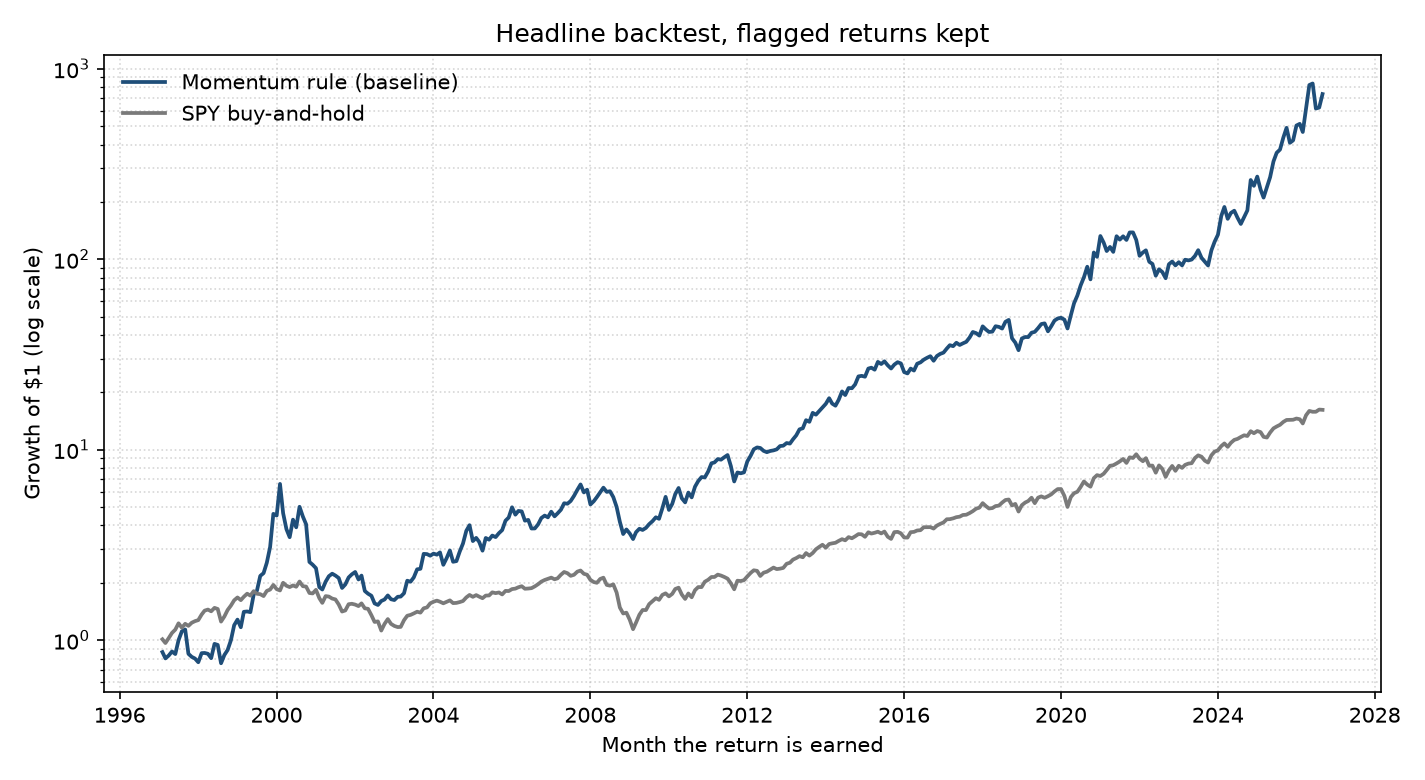

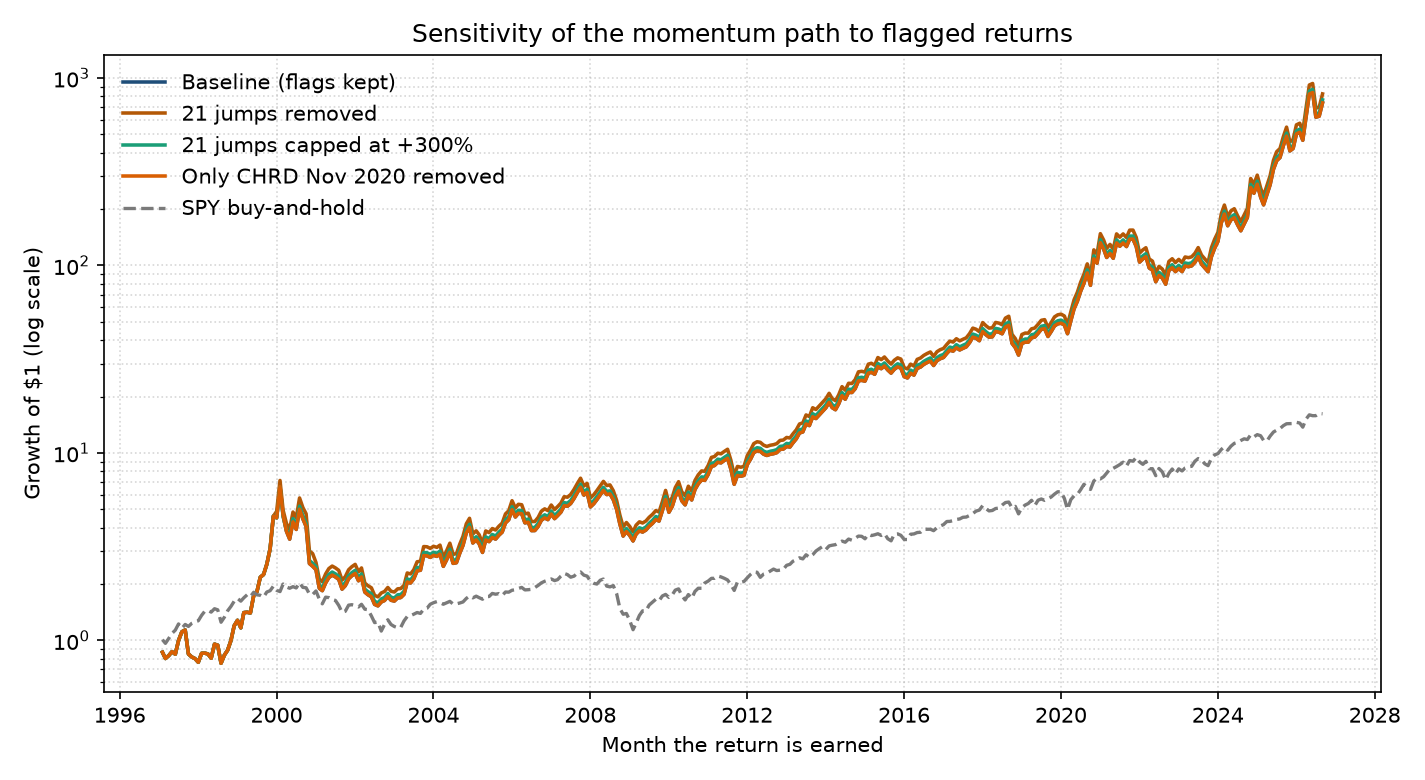

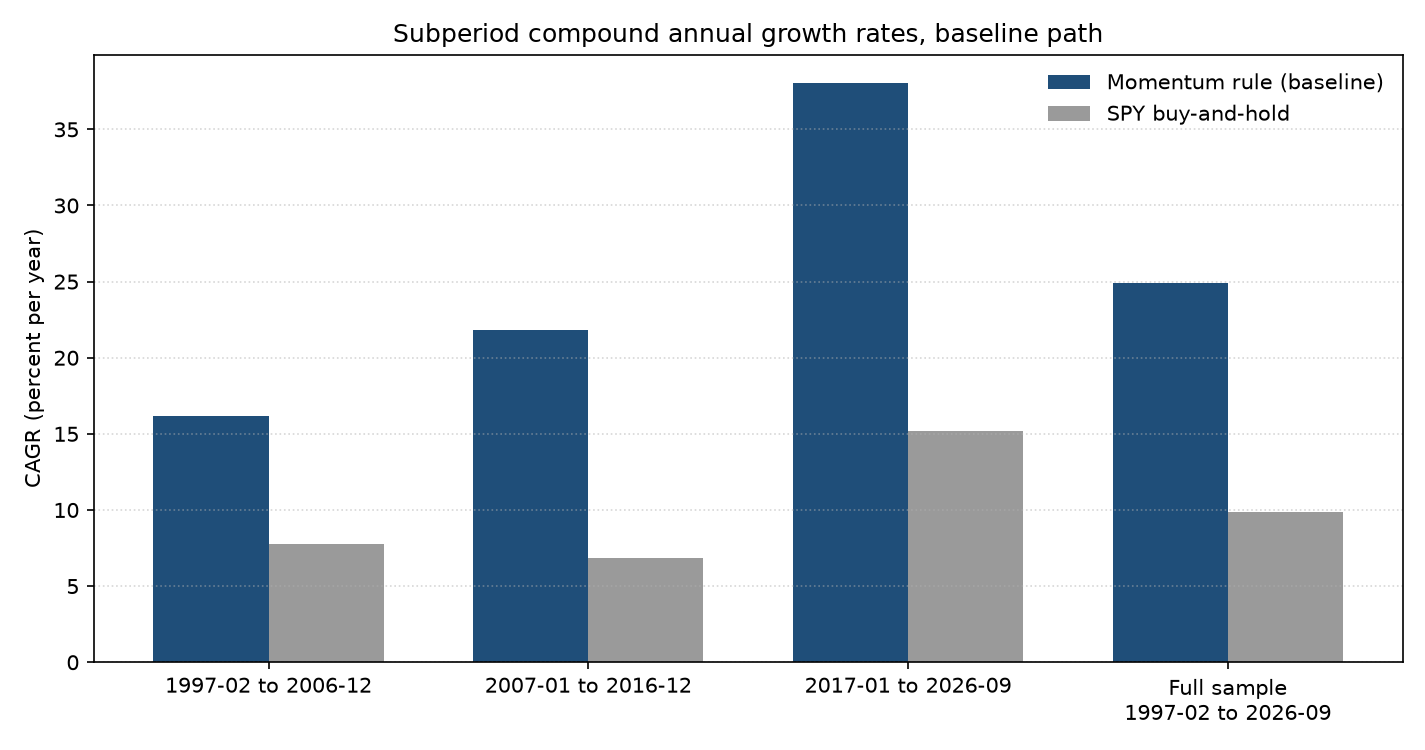

In [13]:
# Figures: growth of $1 on the baseline, growth under each sensitivity path, and subperiod CAGRs.
def month_end_stamps(bt):
    # Plot at the month the return is earned (pick month + 1).
    return pd.PeriodIndex(bt["month"], freq="M").to_timestamp(how="end") + pd.offsets.MonthBegin(1)


fig, ax = plt.subplots(figsize=(9.5, 5.2))
t = month_end_stamps(bt_baseline)
ax.plot(t, bt_baseline["strategy_growth"], color="#1f4e79", lw=1.8, label="Momentum rule (baseline)")
ax.plot(t, bt_baseline["spy_growth"], color="#7a7a7a", lw=1.8, label="SPY buy-and-hold")
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_xlabel("Month the return is earned")
ax.set_title("Headline backtest, flagged returns kept")
ax.legend(frameon=False, loc="upper left")
ax.grid(True, which="both", ls=":", alpha=0.5)
fig.tight_layout()
growth_path = FIGURES / "growth_baseline.png"
fig.savefig(growth_path, dpi=150)
plt.close(fig)
print("wrote", growth_path)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
styles = {
    "baseline": ("#1f4e79", "Baseline (flags kept)"),
    "exclude_flagged": ("#b35806", "21 jumps removed"),
    "cap_300": ("#1b9e77", "21 jumps capped at +300%"),
    "exclude_chrd_2020_11": ("#d95f02", "Only CHRD Nov 2020 removed"),
}
for key, (color, label) in styles.items():
    bt = backtests[key]
    ax.plot(month_end_stamps(bt), bt["strategy_growth"], color=color, lw=1.7, label=label)
ax.plot(month_end_stamps(bt_baseline), bt_baseline["spy_growth"], color="#7a7a7a", lw=1.6,
        ls="--", label="SPY buy-and-hold")
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_xlabel("Month the return is earned")
ax.set_title("Sensitivity of the momentum path to flagged returns")
ax.legend(frameon=False, loc="upper left")
ax.grid(True, which="both", ls=":", alpha=0.5)
fig.tight_layout()
sens_path = FIGURES / "growth_sensitivity.png"
fig.savefig(sens_path, dpi=150)
plt.close(fig)
print("wrote", sens_path)

fig, ax = plt.subplots(figsize=(9.5, 5.0))
labels = []
strat_vals = []
spy_vals = []
for name, start, end in SUBPERIODS:
    s = sub_stats[name]
    labels.append(f"{s['first_month']} to {s['last_month']}")
    strat_vals.append(s["cagr_strategy"] * 100)
    spy_vals.append(s["cagr_spy"] * 100)
# Also show the full-sample CAGRs for reference.
labels.append(f"Full sample\n{sum_baseline['first_month']} to {sum_baseline['last_month']}")
strat_vals.append(sum_baseline["cagr_strategy"] * 100)
spy_vals.append(sum_baseline["cagr_spy"] * 100)
x = np.arange(len(labels))
w = 0.36
ax.bar(x - w / 2, strat_vals, width=w, color="#1f4e79", label="Momentum rule (baseline)")
ax.bar(x + w / 2, spy_vals, width=w, color="#9a9a9a", label="SPY buy-and-hold")
ax.set_xticks(x, labels)
ax.set_ylabel("CAGR (percent per year)")
ax.set_title("Subperiod compound annual growth rates, baseline path")
ax.legend(frameon=False, loc="upper right")
ax.grid(True, axis="y", ls=":", alpha=0.5)
fig.tight_layout()
sub_path = FIGURES / "subperiod_cagr.png"
fig.savefig(sub_path, dpi=150)
plt.close(fig)
print("wrote", sub_path)

from IPython.display import Image, display

for path in (growth_path, sens_path, sub_path):
    display(Image(filename=str(path)))


**Changes since P3, dated 2026-11-17.** The raw Nasdaq file, the Yahoo cache, the universe filter, the join, and the headline rule (keep the 21 flagged returns) are unchanged. P4 adds the download script, the sensitivity paths, the bootstrap and subperiod checks, `results/findings.csv`, and the figures above. Yahoo was not pulled again. The current directory still omits later-delisted firms, and the six skipped tickers are still missing from the price table. Those limits are not fixed by the sensitivity checks. Every number used in the report should be read from `results/findings.csv` or from the printed backtest summaries in this notebook.
